In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, probplot

plt.style.use("seaborn-v0_8")
sns.set_palette("Set2")


In [4]:
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")
df.head()


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [5]:
crosstab = pd.crosstab(df["category"], df["isBestSeller"])
crosstab.head()


isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3


In [6]:
best_seller_prop = (
    crosstab.div(crosstab.sum(axis=1), axis=0)[True]
    .sort_values(ascending=False)
)

best_seller_prop.head(10)


category
Grocery                           0.058135
Smart Home Security & Lighting    0.057692
Health & Personal Care            0.057686
Mobile Phone Accessories          0.042471
Power & Hand Tools                0.035339
Billiard, Snooker & Pool          0.032129
Pet Supplies                      0.030200
Home Brewing & Wine Making        0.028455
Wind Instruments                  0.028000
Mirrors                           0.028000
Name: True, dtype: float64

In [7]:
chi2, p_value, dof, expected = chi2_contingency(crosstab)

chi2, p_value


(36540.20270061387, 0.0)

In [8]:
n = crosstab.sum().sum()
cramers_v = np.sqrt(chi2 / (n * (min(crosstab.shape) - 1)))
cramers_v


0.1222829439760564

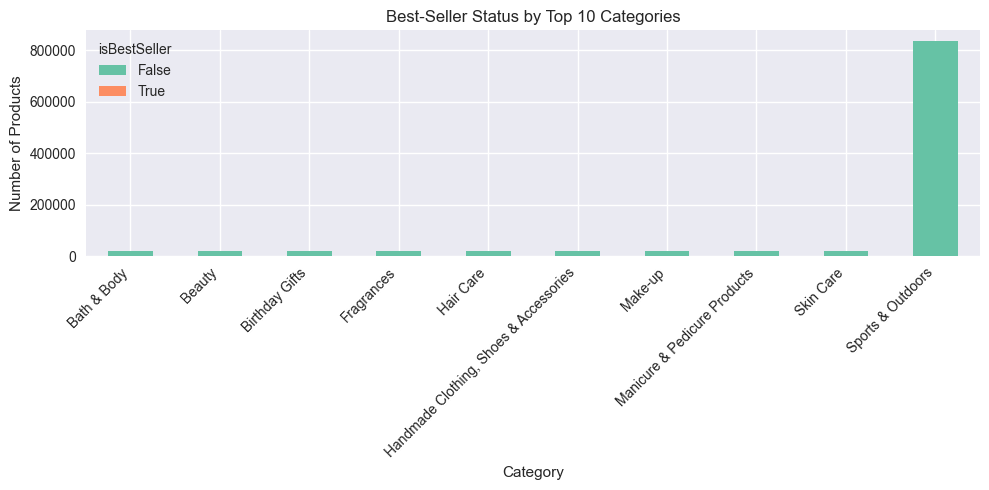

In [9]:
top10_categories = df["category"].value_counts().head(10).index

crosstab_top10 = pd.crosstab(
    df[df["category"].isin(top10_categories)]["category"],
    df["isBestSeller"]
)

crosstab_top10.plot(
    kind="bar",
    stacked=True,
    figsize=(10,5)
)

plt.title("Best-Seller Status by Top 10 Categories")
plt.xlabel("Category")
plt.ylabel("Number of Products")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [10]:
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_no_outliers = df[
    (df["price"] >= lower_bound) &
    (df["price"] <= upper_bound)
]

df_no_outliers.shape


(2115963, 9)

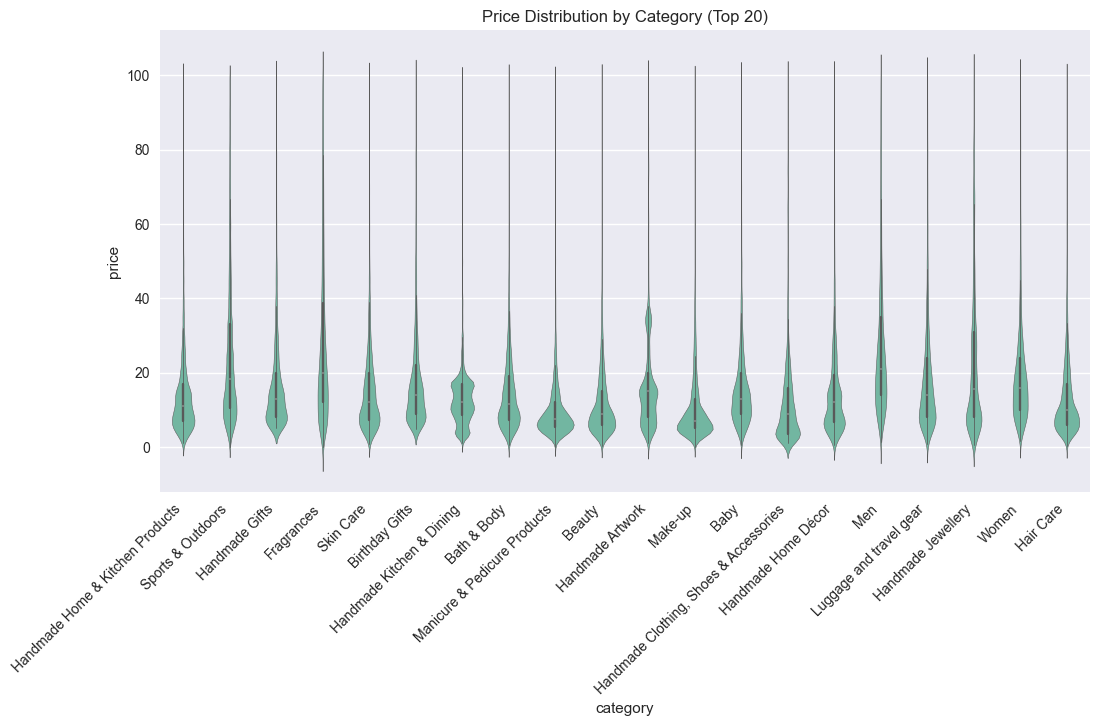

In [11]:
top20_categories = df_no_outliers["category"].value_counts().head(20).index

plt.figure(figsize=(12,6))
sns.violinplot(
    data=df_no_outliers[df_no_outliers["category"].isin(top20_categories)],
    x="category",
    y="price"
)
plt.xticks(rotation=45, ha="right")
plt.title("Price Distribution by Category (Top 20)")
plt.show()


In [12]:
median_price_by_cat = (
    df_no_outliers.groupby("category")["price"].median()
    .sort_values(ascending=False)
)

median_price_by_cat.head()


category
Desktop PCs       74.00
Boxing Shoes      69.79
Tablets           69.00
Graphics Cards    68.54
Motherboards      67.92
Name: price, dtype: float64

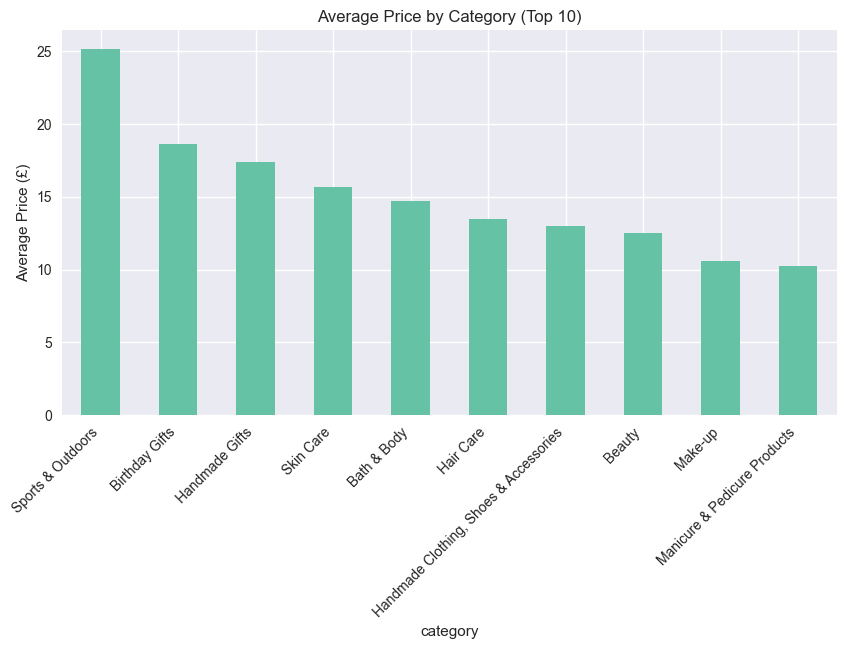

In [13]:
top10_categories = df_no_outliers["category"].value_counts().head(10).index

avg_price_top10 = (
    df_no_outliers[df_no_outliers["category"].isin(top10_categories)]
    .groupby("category")["price"]
    .mean()
    .sort_values(ascending=False)
)

avg_price_top10.plot(kind="bar", figsize=(10,5))
plt.title("Average Price by Category (Top 10)")
plt.ylabel("Average Price (£)")
plt.xticks(rotation=45, ha="right")
plt.show()


In [14]:
df_no_outliers.groupby("category")["price"].mean().sort_values(ascending=False).head()


category
Motherboards      68.772432
Boxing Shoes      67.417803
Desktop PCs       66.915562
Tablets           66.552971
Graphics Cards    65.103509
Name: price, dtype: float64

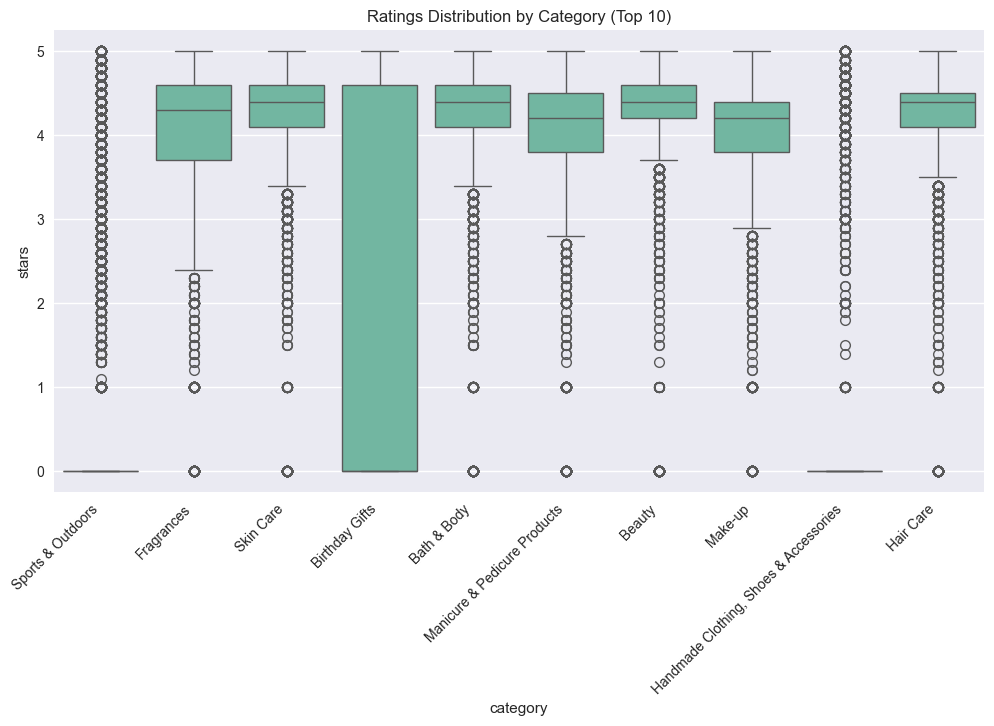

In [15]:
top10_categories = df["category"].value_counts().head(10).index

plt.figure(figsize=(12,6))
sns.boxplot(
    data=df[df["category"].isin(top10_categories)],
    x="category",
    y="stars"
)
plt.xticks(rotation=45, ha="right")
plt.title("Ratings Distribution by Category (Top 10)")
plt.show()


In [16]:
df.groupby("category")["stars"].median().sort_values(ascending=False).head()


category
Computer Memory         4.7
Hobbies                 4.6
Beer, Wine & Spirits    4.6
Laptop Accessories      4.6
Kids' Play Figures      4.6
Name: stars, dtype: float64

In [17]:
correlation = df_no_outliers["price"].corr(df_no_outliers["stars"])
correlation


-0.07767299878181443

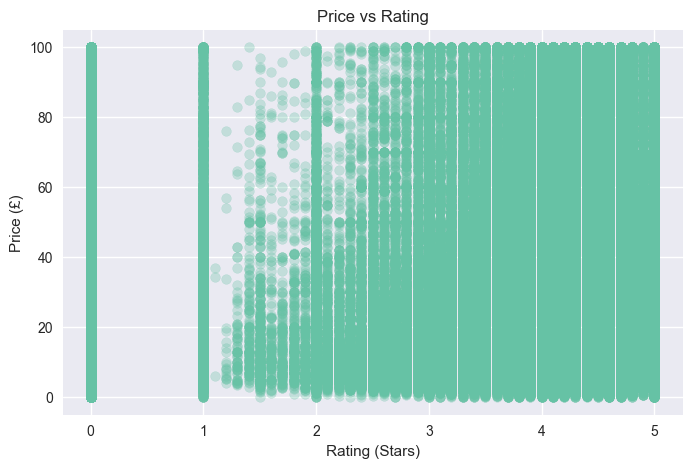

In [18]:
plt.figure(figsize=(8,5))
plt.scatter(df_no_outliers["stars"], df_no_outliers["price"], alpha=0.3)
plt.xlabel("Rating (Stars)")
plt.ylabel("Price (£)")
plt.title("Price vs Rating")
plt.show()


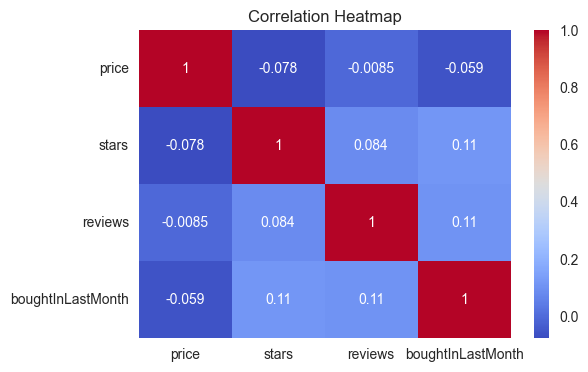

In [19]:
numerical_cols = df_no_outliers[["price", "stars", "reviews", "boughtInLastMonth"]]

plt.figure(figsize=(6,4))
sns.heatmap(
    numerical_cols.corr(),
    annot=True,
    cmap="coolwarm"
)
plt.title("Correlation Heatmap")
plt.show()


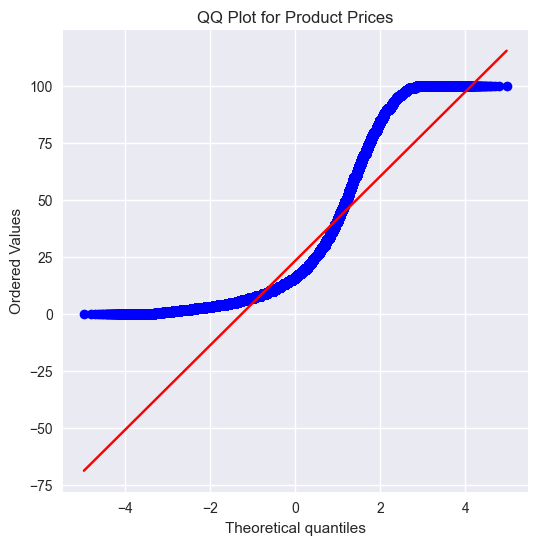

In [20]:
plt.figure(figsize=(6,6))
probplot(df_no_outliers["price"], plot=plt)
plt.title("QQ Plot for Product Prices")
plt.show()


In [21]:
df["price"].corr(df["stars"])


-0.12490673262148386